# Experiment 5.1 — Imputation Fix Delta on Experiment 5

**What this is:** a one-line correctness fix on top of `kp-experiment-5.ipynb`. Nothing
else changes — same features, same CV folds, same hyperparameter grid, same ensemble
composition, same multi-seed averaging, same submission writer. The only difference is
in `impute_domain_features` (§2 cell), which is now `ffill().bfill()` within series
(sorted by timestamp) instead of `ffill().fillna(0)`.

**Why:** `data-analysis-2.ipynb` §2-4 verified that:

- Gap lengths in the 10 missing-prone forecast features are uniformly short (max 4h
  across all 960 series × feature pairs, mean ~1.05h, p99 ≤ 3h).
- Missingness is independent across columns (pairwise NaN-mask correlation ≤ 0.004)
  and effectively MCAR in time (≤ 0.81 pp hour-of-day deviation).

Given that, `ffill` handles the bulk of NaNs correctly, but the rare leading-NaN
case (a series whose first timestamps are NaN for some feature) was previously
filled with **zero** — a value far from the typical range for these features. `bfill`
uses the next valid value instead, which is essentially always closer to the truth.

**Expected impact:** small. Best guess Δ ≈ 0 to −0.05 CV-WAPE, well within the
fold-to-fold standard deviation of ±0.64. This notebook is run primarily as a
**correctness check**, not as a feature-engineering win. If it lands within ±0.1
of the exp-5 numbers, treat it as a confirmation that the fix is harmless and
adopt it going forward. If it regresses by more than that, dig in — something
unexpected is happening with those leading-NaN rows.

**Acceptance:** §4 should land at CV-WAPE 14.80 ± noise; the four downstream
sections (§5-§8) should land within the same noise band of their exp-5 results.

---

**Original exp-5 narrative (everything below is unchanged from `kp-experiment-5.ipynb`):**

**Starting point:** experiment-4 best config = LightGBM-MAE + `sid_code` categorical
+ temporal context (lags / leads / rolling of top 5 covariates) → **CV-WAPE 14.80 ± 0.64**.

**Goal:** stack four orthogonal improvements and push CV-WAPE to ~14.3-14.5.

| Step | What | Expected ΔWAPE |
|------|------|---------------:|
| §5 | Hyperparameter tuning (grid over `lr`, `num_leaves`, `min_child_samples`) | −0.1 to −0.3 |
| §6 | Bias correction (per-series additive shift on OOF residuals, leave-one-fold-out) | −0.1 to −0.3 |
| §7 | Multi-objective ensemble (MAE + Poisson + Tweedie + Ridge, OOF-tuned weights) | −0.2 to −0.4 |
| §8 | Multi-seed averaging (5 seeds of best config, simple mean) | −0.05 to −0.15 |
| §9 | Combine all + refit on full data + save submission | (—) |

**Discipline:** all configuration sits in §0; every following section follows the same
shape (rationale → code → outcome); submission packaging is isolated in §9 so it does
not pollute the analysis.

---
## §0. Configuration

Everything that you might want to tweak lives in this one cell.

In [3]:
from pathlib import Path

# ── Paths ─────────────────────────────────────────────────────────────────────
# Kaggle paths (uncomment when running on Kaggle):
DATA_DIR     = Path("/kaggle/input/datasets/xitij27/dlam-bonus-project-dataset/data")
OUTPUT_DIR   = Path("/kaggle/working")
# Local paths (default):
# DATA_DIR     = Path("data")
# OUTPUT_DIR   = Path("experiment-5")

TRAIN_PATH     = DATA_DIR / "train.csv"
VAL_INPUT_PATH = DATA_DIR / "validation_input.csv"
VAL_INDEX_PATH = DATA_DIR / "forecast_index_validation.csv"

# ── Reproducibility ──────────────────────────────────────────────────────────
SEED         = 42
N_FOLDS      = 3
EVAL_HORIZON = 336      # 14-day forecast window (hours)

# ── Feature config ───────────────────────────────────────────────────────────
DOMAIN_FEAT_COLS = [
    "workload_intensity", "demand_forecast", "upstream_quality_forecast",
    "promotion_intensity", "shock_risk", "maintenance_known",
    "unit_reliability_forecast", "queue_pressure_forecast",
    "network_pressure_forecast", "event_load_forecast",
    "service_irregularity_risk_forecast",
]
TIME_COLS = ["hour_sin", "hour_cos", "dow_sin", "dow_cos",
             "doy_sin", "doy_cos", "is_weekend"]

# Top 5 covariates (by OOS R²) — get lag/lead temporal context
TOP_DOM    = ["queue_pressure_forecast", "network_pressure_forecast",
              "workload_intensity", "shock_risk", "event_load_forecast"]
TOP3_ROLL  = TOP_DOM[:3]                # top 3 also get rolling-window stats
LAGS_DOM   = [1, 24]
LEADS_DOM  = [1, 24]
ROLL_WINS  = [6, 24]

# ── Baseline LightGBM (exp-4 best — tuned in §5) ─────────────────────────────
BASELINE_LGBM = dict(
    n_estimators=600, learning_rate=0.03, num_leaves=63,
    subsample=0.8, colsample_bytree=0.8, min_child_samples=50,
    reg_lambda=1.0, verbose=-1,
)

# Tuning grid for §5
TUNE_GRID = {
    "learning_rate":      [0.02, 0.03, 0.05],
    "num_leaves":         [31, 63, 127],
    "min_child_samples":  [20, 50, 100],
    "n_estimators":       [600, 800],
}

# Multi-seed ensemble (§8)
SEEDS_ENSEMBLE = [42, 101, 202, 303, 404]

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"DATA_DIR = {DATA_DIR}")
print(f"OUTPUT_DIR = {OUTPUT_DIR}")
print(f"CV folds: {N_FOLDS}, horizon: {EVAL_HORIZON}h")

DATA_DIR = /kaggle/input/datasets/xitij27/dlam-bonus-project-dataset/data
OUTPUT_DIR = /kaggle/working
CV folds: 3, horizon: 336h


---
## §1. Setup & Data Loading

In [4]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from scipy.optimize import minimize

np.random.seed(SEED)

def wape(y_true, y_pred, eps=1e-8):
    return np.sum(np.abs(np.asarray(y_true) - np.asarray(y_pred))) / \
           (np.sum(np.abs(y_true)) + eps) * 100

# Load
train_df  = pd.read_csv(TRAIN_PATH,     parse_dates=["timestamp"])
val_input = pd.read_csv(VAL_INPUT_PATH, parse_dates=["timestamp"])
val_index = pd.read_csv(VAL_INDEX_PATH, parse_dates=["timestamp"])

# Stable series_id → integer code (sorted alphabetically so it is reproducible)
sid_to_code = {sid: i for i, sid in enumerate(sorted(train_df["series_id"].unique()))}

print(f"train_df:  {train_df.shape}")
print(f"val_input: {val_input.shape}")
print(f"val_index: {val_index.shape}")
print(f"# series:  {len(sid_to_code)}")

train_df:  (414720, 25)
val_input: (32256, 24)
val_index: (32256, 2)
# series:  96


---
## §2. Feature Engineering

Same feature pipeline as experiment-4 §8 (the best config so far):

- **Domain features**: 11 forecast columns, imputed with `ffill().bfill()` within each `series_id` (sorted by `timestamp`). See exp-5.1 header for rationale; was `ffill().fillna(0)` in exp-5.
- **Time encodings**: 7 cyclical features from `timestamp`.
- **`series_mean`**: per-series training-mean of the target (leakage-free, recomputed per fold).
- **`sid_code`**: integer encoding of `series_id` for native LightGBM categorical handling.
- **Temporal context** (32 features): lags `[1, 24]` and leads `[1, 24]` of the top 5
  covariates, plus rolling mean/std over 6h and 24h windows for the top 3.

Total feature count: 11 + 7 + 1 + 1 + 32 = **52 features**.

In [5]:
def impute_domain_features(df, cols):
    # exp-5.1: was ffill().fillna(0); now ffill().bfill() with an explicit sort.
    # Rationale: data-analysis-2.ipynb §2 showed gaps are uniformly ≤ 4h with strong
    # local autocorrelation, so bfill on the leading-NaN edge case beats zero-fill.
    # Sort makes the function order-independent of how `df` was loaded.
    df = df.sort_values(["series_id", "timestamp"]).copy()
    df[cols] = df.groupby("series_id", group_keys=False)[cols].transform(
        lambda x: x.ffill().bfill()
    )
    return df

def add_time_features(df, time_col="timestamp"):
    df = df.copy()
    t = pd.to_datetime(df[time_col])
    df["hour_sin"]   = np.sin(2 * np.pi * t.dt.hour / 24)
    df["hour_cos"]   = np.cos(2 * np.pi * t.dt.hour / 24)
    df["dow_sin"]    = np.sin(2 * np.pi * t.dt.dayofweek / 7)
    df["dow_cos"]    = np.cos(2 * np.pi * t.dt.dayofweek / 7)
    df["doy_sin"]    = np.sin(2 * np.pi * t.dt.dayofyear / 365)
    df["doy_cos"]    = np.cos(2 * np.pi * t.dt.dayofyear / 365)
    df["is_weekend"] = (t.dt.dayofweek >= 5).astype(float)
    return df

def add_temporal_features(df, lag_cols, roll_cols, lags, leads, windows):
    "Adds lag/lead and rolling features for known covariates. Returns df, new_col_names."
    df = df.copy().sort_values(["series_id", "timestamp"])
    new = []
    for col in lag_cols:
        g = df.groupby("series_id", sort=False)[col]
        for L in lags:
            c = f"{col}_lag{L}";  df[c] = g.shift(L);  new.append(c)
        for L in leads:
            c = f"{col}_lead{L}"; df[c] = g.shift(-L); new.append(c)
    for col in roll_cols:
        g = df.groupby("series_id", sort=False)[col]
        for W in windows:
            c_m = f"{col}_roll{W}m"
            df[c_m] = g.shift(1).transform(lambda x: x.rolling(W, min_periods=1).mean())
            new.append(c_m)
            c_s = f"{col}_roll{W}s"
            df[c_s] = g.shift(1).transform(lambda x: x.rolling(W, min_periods=1).std().fillna(0))
            new.append(c_s)
    return df, new

# Build the full feature frame on train.csv ONCE (CV reuses it)
base = add_time_features(impute_domain_features(train_df, DOMAIN_FEAT_COLS))
base["sid_code"] = base["series_id"].map(sid_to_code).astype("int32")
base, TEMPORAL_FEATS = add_temporal_features(
    base, lag_cols=TOP_DOM, roll_cols=TOP3_ROLL,
    lags=LAGS_DOM, leads=LEADS_DOM, windows=ROLL_WINS,
)

NUMERIC_FEATS  = DOMAIN_FEAT_COLS + TIME_COLS + ["series_mean"] + TEMPORAL_FEATS
FEATS_WITH_SID = NUMERIC_FEATS + ["sid_code"]

print(f"Feature breakdown:")
print(f"  Domain forecasts   : {len(DOMAIN_FEAT_COLS)}")
print(f"  Time encodings     : {len(TIME_COLS)}")
print(f"  series_mean        : 1")
print(f"  sid_code           : 1")
print(f"  Temporal context   : {len(TEMPORAL_FEATS)}")
print(f"  ─────────────────────────────")
print(f"  Total              : {len(FEATS_WITH_SID)}")

Feature breakdown:
  Domain forecasts   : 11
  Time encodings     : 7
  series_mean        : 1
  sid_code           : 1
  Temporal context   : 32
  ─────────────────────────────
  Total              : 52


---
## §3. CV Framework

Same 3-fold rolling-origin CV as experiment-4. Each fold uses an expanding training
window, and the test block is 336 hours per series at the tail. `series_mean` is
recomputed per fold using only that fold's training portion to stay leakage-free.

Fold offsets:
- Fold 0: train days 1-138,  test 139-152
- Fold 1: train days 1-152,  test 153-166
- Fold 2: train days 1-166,  test 167-180

In [6]:
def fold_split(end_off, length=EVAL_HORIZON):
    "Split `base` into (train, test) for a given fold; recomputes series_mean leakage-free."
    tr_list, te_list = [], []
    for _, g in base.groupby("series_id", sort=False):
        g = g.sort_values("timestamp")
        cut = len(g) - end_off
        tr_list.append(g.iloc[:cut])
        te_list.append(g.iloc[cut:cut + length])
    tr = pd.concat(tr_list, ignore_index=True)
    te = pd.concat(te_list, ignore_index=True)
    sm = tr.groupby("series_id")["target"].mean().rename("series_mean").reset_index()
    return tr.merge(sm, on="series_id"), te.merge(sm, on="series_id")

def fold_offset(k):
    return (N_FOLDS - k) * EVAL_HORIZON

def fit_and_predict(tr, te, feats, params, objective, categorical=None, seed=SEED):
    "Fit one LightGBM and return predictions on `te`."
    model = lgb.LGBMRegressor(**params, objective=objective, random_state=seed)
    fit_kw = {} if not categorical else {"categorical_feature": categorical}
    model.fit(tr[feats], tr["target"].to_numpy(float), **fit_kw)
    return model.predict(te[feats]), model

def cv_score(feats, params, objective, categorical=None, seed=SEED, return_oof=False):
    "3-fold CV — returns mean WAPE (and optionally OOF predictions DataFrame)."
    per_fold, oof_rows = [], []
    for k in range(N_FOLDS):
        tr, te = fold_split(fold_offset(k))
        preds, _ = fit_and_predict(tr, te, feats, params, objective, categorical, seed)
        per_fold.append(wape(te["target"], preds))
        if return_oof:
            oof_rows.append(te.assign(pred=preds, fold=k)[["series_id","timestamp","target","pred","fold"]])
    arr = np.array(per_fold)
    if return_oof:
        return arr, pd.concat(oof_rows, ignore_index=True)
    return arr

print("CV framework ready.")

CV framework ready.


---
## §4. Reproduce the experiment-4 baseline

Before any improvement work, confirm that this notebook's CV setup reproduces the
experiment-4 final number (CV-WAPE 14.80 ± 0.64). If it doesn't, the rest of the
notebook is meaningless — a mismatch here points at a data, feature, or split bug.

In [7]:
print("Running baseline (MAE + sid_code categorical + temporal features)...")
baseline_arr = cv_score(FEATS_WITH_SID, BASELINE_LGBM, "regression_l1",
                         categorical=["sid_code"])
print()
print(f"{'fold':>6}  {'WAPE':>8}")
for k, w in enumerate(baseline_arr): print(f"  {k:4d}    {w:>7.3f}")
print(f"  ────")
print(f"  mean    {baseline_arr.mean():>7.3f}")
print(f"  std     {baseline_arr.std():>7.3f}")

if abs(baseline_arr.mean() - 14.80) < 0.5:
    print()
    print("✅ Baseline reproduces experiment-4 (within 0.5 WAPE). Proceeding with improvements.")
else:
    print()
    print(f"⚠️  Baseline differs from expected 14.80 by {abs(baseline_arr.mean() - 14.80):.2f}.")
    print("    Investigate before continuing.")

BASELINE_WAPE = baseline_arr.mean()
BASELINE_STD  = baseline_arr.std()
BASELINE_PER_FOLD = baseline_arr.copy()

Running baseline (MAE + sid_code categorical + temporal features)...

  fold      WAPE
     0     14.082
     1     15.581
     2     14.683
  ────
  mean     14.782
  std       0.616

✅ Baseline reproduces experiment-4 (within 0.5 WAPE). Proceeding with improvements.


---
## §5. Step 1 — Hyperparameter Tuning

**Rationale:** experiment-4 used a single hyperparameter setting that was reasonable
but not tuned under CV. A small grid search can typically pick up 0.1-0.3 WAPE.

**Approach:** sample 8 random configurations from the grid in `TUNE_GRID` and evaluate
each under the same 3-fold CV. Pick the best by mean WAPE. Random sampling instead of
full grid (54 configs) keeps runtime under 5 minutes.

**Decision rule:** accept the new config only if it beats the baseline by more than
half the baseline std (≈ 0.32). Smaller "improvements" are likely noise.

In [8]:
import itertools, random
random.seed(SEED)

all_configs = list(itertools.product(
    TUNE_GRID["learning_rate"],
    TUNE_GRID["num_leaves"],
    TUNE_GRID["min_child_samples"],
    TUNE_GRID["n_estimators"],
))
sample_configs = random.sample(all_configs, k=min(8, len(all_configs)))

tune_results = []
print(f"{'#':>3}  {'lr':>6}  {'leaves':>6}  {'minch':>6}  {'nest':>5}  {'fold0':>7}  {'fold1':>7}  {'fold2':>7}  {'mean':>7}  {'std':>6}")
print("-" * 84)
for i, (lr, leaves, minch, nest) in enumerate(sample_configs):
    params = dict(BASELINE_LGBM)
    params.update(learning_rate=lr, num_leaves=leaves, min_child_samples=minch, n_estimators=nest)
    arr = cv_score(FEATS_WITH_SID, params, "regression_l1", categorical=["sid_code"])
    tune_results.append({
        "lr": lr, "num_leaves": leaves, "min_child_samples": minch, "n_estimators": nest,
        "f0": arr[0], "f1": arr[1], "f2": arr[2], "mean": arr.mean(), "std": arr.std(),
    })
    print(f"  {i:>2}  {lr:>6.2f}  {leaves:>6d}  {minch:>6d}  {nest:>5d}  "
          f"{arr[0]:>7.3f}  {arr[1]:>7.3f}  {arr[2]:>7.3f}  {arr.mean():>7.3f}  {arr.std():>6.3f}")

tune_df = pd.DataFrame(tune_results).sort_values("mean").reset_index(drop=True)
print()
print("Best 3 configurations:")
display(tune_df.head(3))

best_tune = tune_df.iloc[0]
TUNED_PARAMS = dict(BASELINE_LGBM)
TUNED_PARAMS.update(
    learning_rate     = best_tune["lr"],
    num_leaves        = int(best_tune["num_leaves"]),
    min_child_samples = int(best_tune["min_child_samples"]),
    n_estimators      = int(best_tune["n_estimators"]),
)
delta = BASELINE_WAPE - best_tune["mean"]
print()
print(f"Baseline    : {BASELINE_WAPE:.3f} ± {BASELINE_STD:.3f}")
print(f"Best tuned  : {best_tune['mean']:.3f} ± {best_tune['std']:.3f}")
print(f"ΔWAPE       : {delta:+.3f}  (negative = improvement)")
if delta > BASELINE_STD * 0.5:
    print("✅ Improvement exceeds half the baseline std — adopt tuned config.")
    STEP1_PARAMS = TUNED_PARAMS
    STEP1_WAPE   = best_tune["mean"]
else:
    print("⚠️  Improvement is within noise. Keeping baseline params.")
    STEP1_PARAMS = BASELINE_LGBM
    STEP1_WAPE   = BASELINE_WAPE

  #      lr  leaves   minch   nest    fold0    fold1    fold2     mean     std
------------------------------------------------------------------------------------
   0    0.05      31     100    600   14.066   15.649   14.697   14.804   0.651
   1    0.02      63      20    800   14.124   15.589   14.643   14.785   0.607
   2    0.02      31      20    800   14.159   15.696   14.758   14.871   0.632
   3    0.05      63     100    800   14.102   15.709   14.687   14.833   0.664
   4    0.02     127     100    800   14.073   15.606   14.631   14.770   0.634
   5    0.02     127      50    800   14.072   15.603   14.671   14.782   0.630
   6    0.02     127      50    600   14.105   15.606   14.703   14.805   0.617
   7    0.02      63      50    600   14.186   15.659   14.696   14.847   0.611

Best 3 configurations:


,lr,num_leaves,min_child_samples,n_estimators,f0,f1,f2,mean,std
0,0.02,127,100,800,14.073344,15.606236,14.630838,14.770139,0.633505
1,0.02,127,50,800,14.072319,15.602935,14.670720,14.781991,0.629805
2,0.02,63,20,800,14.123548,15.588962,14.643179,14.785230,0.606626



Baseline    : 14.782 ± 0.616
Best tuned  : 14.770 ± 0.634
ΔWAPE       : +0.012  (negative = improvement)
⚠️  Improvement is within noise. Keeping baseline params.


---
## §6. Step 2 — Bias Correction

**Rationale:** LightGBM with the MAE objective finds the conditional **median**, not the mean.
For a right-skewed target (skew = 0.98 in §5 of the data analysis), the median sits below
the mean — so MAE-trained models slightly under-predict on average. Experiment-4 §8 noted
this directly: "Mean bias was −0.48 in the final model."

A per-series additive correction fits a single constant per series on out-of-fold residuals
and adds it to the prediction at inference time. This is a free WAPE win for any
MAE-trained model: the per-series bias is the only thing that has to be estimated, and
it can be done on the OOF predictions.

**Honesty:** to avoid the slight optimism of fitting the bias on the same fold's
predictions, use **leave-one-fold-out**: for fold k's predictions, compute the bias from
folds `{0..N-1} \ {k}` and apply it to fold k. Then aggregate WAPE across all corrected folds.

In [9]:
# Step A: get OOF predictions from the chosen Step-1 config (objective = MAE, sid categorical)
print("Computing OOF predictions for Step-1 model...")
arr_step1, oof_step1 = cv_score(FEATS_WITH_SID, STEP1_PARAMS, "regression_l1",
                                  categorical=["sid_code"], return_oof=True)
print(f"  Step-1 CV-WAPE: {arr_step1.mean():.3f} ± {arr_step1.std():.3f}")

# Step B: leave-one-fold-out bias estimation
oof_step1["residual"] = oof_step1["target"] - oof_step1["pred"]

corrected_per_fold = []
for k in range(N_FOLDS):
    other_folds = oof_step1[oof_step1["fold"] != k]
    bias_k = other_folds.groupby("series_id")["residual"].mean()
    this_fold = oof_step1[oof_step1["fold"] == k].copy()
    this_fold["bias"] = this_fold["series_id"].map(bias_k).fillna(0)
    this_fold["pred_corr"] = this_fold["pred"] + this_fold["bias"]
    w_uncorr = wape(this_fold["target"], this_fold["pred"])
    w_corr   = wape(this_fold["target"], this_fold["pred_corr"])
    corrected_per_fold.append((k, w_uncorr, w_corr))

print()
print(f"{'fold':>6}  {'uncorr':>7}  {'corrected':>10}  {'Δ':>7}")
for k, wu, wc in corrected_per_fold:
    print(f"  {k:>4}  {wu:>7.3f}  {wc:>10.3f}  {wu-wc:>+7.3f}")

mean_corr = np.mean([wc for _, _, wc in corrected_per_fold])
mean_uncorr = np.mean([wu for _, wu, _ in corrected_per_fold])
delta = mean_uncorr - mean_corr

print()
print(f"Step-1 (uncorrected): {mean_uncorr:.3f}")
print(f"Step-2 (corrected)  : {mean_corr:.3f}")
print(f"ΔWAPE               : {delta:+.3f}  (negative = improvement)")

if delta > 0.05:
    print("✅ Bias correction helps. Will apply at submission time.")
    APPLY_BIAS = True
else:
    print("⚠️  Bias correction effect is negligible. Skipping.")
    APPLY_BIAS = False

STEP2_WAPE = mean_corr if APPLY_BIAS else mean_uncorr

Computing OOF predictions for Step-1 model...
  Step-1 CV-WAPE: 14.782 ± 0.616

  fold   uncorr   corrected        Δ
     0   14.082      14.486   -0.403
     1   15.581      16.882   -1.301
     2   14.683      15.760   -1.077

Step-1 (uncorrected): 14.782
Step-2 (corrected)  : 15.709
ΔWAPE               : -0.927  (negative = improvement)
⚠️  Bias correction effect is negligible. Skipping.


---
## §7. Step 3 — Multi-objective Ensemble

**Rationale:** experiment-4 §7 found that L2, MAE, Poisson, and Tweedie objectives each
landed in a similar WAPE range but with different residual structure. Blending them can
extract diversity gain — provided their errors are not perfectly correlated.

**Approach:**

1. Train four base models on each CV fold:
   - LightGBM with `objective="regression_l1"` (MAE)
   - LightGBM with `objective="poisson"`
   - LightGBM with `objective="tweedie"` (variance_power 1.5 default)
   - Linear Ridge (different model family, brings different inductive bias)

2. Collect OOF predictions for all 4 models.

3. Find blend weights `w ∈ ℝ⁴` that minimize WAPE on the stacked OOF predictions,
   subject to `w ≥ 0` and `sum(w) = 1` (a convex combination — no individual model
   contributes negatively).

4. Apply the optimal weights at submission time.

**Why convex combination:** unconstrained weights can give crazy values that overfit OOF
noise. Convex combinations are stable and interpretable (each weight is a "mixing share").

For the Ridge model we standardize features and use only the numeric features (no `sid_code`).

In [10]:
# Step A: collect OOF predictions for all 4 base models
print("Training 4 base models per fold...")
print(f"{'fold':>6}  {'MAE':>7}  {'Poisson':>8}  {'Tweedie':>8}  {'Ridge':>7}")
print("-" * 44)

oof_records = []
for k in range(N_FOLDS):
    tr, te = fold_split(fold_offset(k))

    # 1. MAE GBM (with sid_code)
    pred_mae, _ = fit_and_predict(tr, te, FEATS_WITH_SID, STEP1_PARAMS, "regression_l1",
                                    categorical=["sid_code"])

    # 2. Poisson GBM (with sid_code)
    pred_poi, _ = fit_and_predict(tr, te, FEATS_WITH_SID, STEP1_PARAMS, "poisson",
                                    categorical=["sid_code"])

    # 3. Tweedie GBM (with sid_code) — default variance_power 1.5
    pred_twe, _ = fit_and_predict(tr, te, FEATS_WITH_SID, STEP1_PARAMS, "tweedie",
                                    categorical=["sid_code"])

    # 4. Linear Ridge (standardized, numeric only)
    scaler = StandardScaler()
    Xtr = scaler.fit_transform(tr[NUMERIC_FEATS].fillna(0))
    Xte = scaler.transform(te[NUMERIC_FEATS].fillna(0))
    ridge = Ridge(alpha=1.0, random_state=SEED).fit(Xtr, tr["target"].to_numpy(float))
    pred_rid = ridge.predict(Xte)

    fold_df = te.assign(pred_mae=pred_mae, pred_poi=pred_poi,
                         pred_twe=pred_twe, pred_rid=pred_rid, fold=k)[
        ["series_id","timestamp","target","pred_mae","pred_poi","pred_twe","pred_rid","fold"]
    ]
    oof_records.append(fold_df)

    print(f"  {k:>4}  "
          f"{wape(te['target'], pred_mae):>7.3f}  "
          f"{wape(te['target'], pred_poi):>8.3f}  "
          f"{wape(te['target'], pred_twe):>8.3f}  "
          f"{wape(te['target'], pred_rid):>7.3f}")

oof_all = pd.concat(oof_records, ignore_index=True)

# Step B: optimize blend weights on stacked OOF
def blend_wape(w, oof):
    blended = (w[0] * oof["pred_mae"] + w[1] * oof["pred_poi"]
             + w[2] * oof["pred_twe"] + w[3] * oof["pred_rid"])
    return wape(oof["target"], blended)

constraints = [{"type": "eq", "fun": lambda w: w.sum() - 1.0}]
bounds      = [(0.0, 1.0)] * 4
init_w      = np.array([0.25, 0.25, 0.25, 0.25])
res = minimize(blend_wape, init_w, args=(oof_all,), method="SLSQP",
               bounds=bounds, constraints=constraints)
BLEND_W = res.x

# Per-fold WAPE under optimal blend
print()
print("Optimal blend weights:")
for name, w in zip(["MAE", "Poisson", "Tweedie", "Ridge"], BLEND_W):
    print(f"  {name:>8}: {w:.4f}")

per_fold_blend = []
for k in range(N_FOLDS):
    f = oof_all[oof_all["fold"] == k]
    blended = (BLEND_W[0] * f["pred_mae"] + BLEND_W[1] * f["pred_poi"]
             + BLEND_W[2] * f["pred_twe"] + BLEND_W[3] * f["pred_rid"])
    per_fold_blend.append(wape(f["target"], blended))

print()
print(f"{'fold':>6}  {'blended':>8}  {'MAE alone':>10}  {'Δ':>7}")
for k in range(N_FOLDS):
    wm = wape(oof_all[oof_all['fold']==k]['target'], oof_all[oof_all['fold']==k]['pred_mae'])
    print(f"  {k:>4}  {per_fold_blend[k]:>8.3f}  {wm:>10.3f}  {wm - per_fold_blend[k]:>+7.3f}")

STEP3_WAPE  = np.mean(per_fold_blend)
STEP3_PER_FOLD = np.array(per_fold_blend)
delta = STEP1_WAPE - STEP3_WAPE

print()
print(f"Step-1 (single MAE)    : {STEP1_WAPE:.3f}")
print(f"Step-3 (4-model blend) : {STEP3_WAPE:.3f}")
print(f"ΔWAPE                  : {delta:+.3f}")
if delta > 0.05:
    print("✅ Ensemble helps. Adopt blend weights.")
    APPLY_ENSEMBLE = True
else:
    print("⚠️  Ensemble gain is negligible. Keeping single MAE model.")
    APPLY_ENSEMBLE = False

Training 4 base models per fold...
  fold      MAE   Poisson   Tweedie    Ridge
--------------------------------------------
     0   14.082    14.751    15.022   16.747
     1   15.581    17.298    17.479   18.925
     2   14.683    15.348    15.837   17.342

Optimal blend weights:
       MAE: 0.8544
   Poisson: 0.0853
   Tweedie: 0.0262
     Ridge: 0.0341

  fold   blended   MAE alone        Δ
     0    14.048      14.082   +0.034
     1    15.553      15.581   +0.027
     2    14.652      14.683   +0.031

Step-1 (single MAE)    : 14.782
Step-3 (4-model blend) : 14.751
ΔWAPE                  : +0.031
⚠️  Ensemble gain is negligible. Keeping single MAE model.


---
## §8. Step 4 — Multi-seed Averaging

**Rationale:** LightGBM with `colsample_bytree < 1` and `subsample < 1` is stochastic in
feature/sample subsampling, so different random seeds produce slightly different models.
Averaging their predictions reduces variance from this stochasticity. Expected gain is
small but free.

**Approach:** train 5 MAE-GBM models with different seeds (sharing the §5 tuned hyperparams),
average predictions on each fold's test set. Report mean ± std.

In [11]:
print(f"Training {len(SEEDS_ENSEMBLE)} seeds × {N_FOLDS} folds = {len(SEEDS_ENSEMBLE) * N_FOLDS} fits...")

per_fold_multiseed = []
for k in range(N_FOLDS):
    tr, te = fold_split(fold_offset(k))
    seed_preds = []
    for s in SEEDS_ENSEMBLE:
        params = dict(STEP1_PARAMS); params["random_state"] = s  # set via params
        # Note: fit_and_predict uses seed arg, simpler to call directly
        model = lgb.LGBMRegressor(**STEP1_PARAMS, objective="regression_l1", random_state=s)
        model.fit(tr[FEATS_WITH_SID], tr["target"], categorical_feature=["sid_code"])
        seed_preds.append(model.predict(te[FEATS_WITH_SID]))
    avg = np.mean(seed_preds, axis=0)
    per_fold_multiseed.append(wape(te["target"], avg))
    print(f"  fold {k}: {len(SEEDS_ENSEMBLE)}-seed avg WAPE = {per_fold_multiseed[-1]:.3f}")

STEP4_WAPE = np.mean(per_fold_multiseed)
STEP4_PER_FOLD = np.array(per_fold_multiseed)
delta = STEP1_WAPE - STEP4_WAPE
print()
print(f"Step-1 (single MAE)     : {STEP1_WAPE:.3f}")
print(f"Step-4 ({len(SEEDS_ENSEMBLE)}-seed avg)      : {STEP4_WAPE:.3f}")
print(f"ΔWAPE                   : {delta:+.3f}")

if delta > 0.02:
    print("✅ Multi-seed averaging helps. Will apply for the final model.")
    APPLY_MULTISEED = True
else:
    print("⚠️  Multi-seed gain is tiny — within noise. Skipping.")
    APPLY_MULTISEED = False

Training 5 seeds × 3 folds = 15 fits...
  fold 0: 5-seed avg WAPE = 14.040
  fold 1: 5-seed avg WAPE = 15.527
  fold 2: 5-seed avg WAPE = 14.619

Step-1 (single MAE)     : 14.782
Step-4 (5-seed avg)      : 14.728
ΔWAPE                   : +0.053
✅ Multi-seed averaging helps. Will apply for the final model.


---
## §9. Final Combined Model & Submission

**Rationale:** apply every improvement that survived its decision check, refit base
models on the FULL training data (concatenated with `validation_input.csv` so the
temporal lag/lead features reach across the train→val boundary), generate predictions,
and write the submission CSV.

**Compose the final predictor:**

1. **Hyperparameters:** §5's tuned config (`STEP1_PARAMS`).
2. **Base models:** if `APPLY_ENSEMBLE`, train MAE + Poisson + Tweedie + Ridge; else just MAE.
3. **Multi-seed:** if `APPLY_MULTISEED`, the MAE component is itself an average over
   `SEEDS_ENSEMBLE`.
4. **Blend:** if ensemble, weights `BLEND_W` from §7; else weight 1.0 on MAE.
5. **Bias correction:** if `APPLY_BIAS`, add per-series shift fit on the full-train OOF
   (computed once over the 3 CV folds).
6. **Clamp at zero:** the target is non-negative.

In [12]:
# Step A: build the inference frame (train + val_input, temporal features cross the boundary)
val_stub = val_input.copy(); val_stub["target"] = np.nan
combined = pd.concat([train_df, val_stub], ignore_index=True)

combined = add_time_features(impute_domain_features(combined, DOMAIN_FEAT_COLS))
combined["sid_code"] = combined["series_id"].map(sid_to_code).astype("int32")

sm_full = train_df.groupby("series_id")["target"].mean().rename("series_mean").reset_index()
combined = combined.merge(sm_full, on="series_id")

combined, _ = add_temporal_features(
    combined, lag_cols=TOP_DOM, roll_cols=TOP3_ROLL,
    lags=LAGS_DOM, leads=LEADS_DOM, windows=ROLL_WINS,
)

train_part = combined[combined["target"].notna()].reset_index(drop=True)
val_part   = combined[combined["target"].isna()].reset_index(drop=True)
print(f"Final train rows: {len(train_part):,}")
print(f"Val rows to predict: {len(val_part):,}")
assert len(val_part) == len(val_input), f"Val row count mismatch: {len(val_part)} vs {len(val_input)}"

# Step B: helper that fits the appropriate base model(s) and produces ensemble predictions
def predict_final(tr_full, te_full):
    "Apply the full pipeline (multi-seed → multi-objective blend) to `te_full`."
    if APPLY_ENSEMBLE:
        # Train MAE (optionally multi-seed)
        if APPLY_MULTISEED:
            mae_preds = []
            for s in SEEDS_ENSEMBLE:
                m = lgb.LGBMRegressor(**STEP1_PARAMS, objective="regression_l1", random_state=s)
                m.fit(tr_full[FEATS_WITH_SID], tr_full["target"], categorical_feature=["sid_code"])
                mae_preds.append(m.predict(te_full[FEATS_WITH_SID]))
            pred_mae = np.mean(mae_preds, axis=0)
        else:
            m = lgb.LGBMRegressor(**STEP1_PARAMS, objective="regression_l1", random_state=SEED)
            m.fit(tr_full[FEATS_WITH_SID], tr_full["target"], categorical_feature=["sid_code"])
            pred_mae = m.predict(te_full[FEATS_WITH_SID])

        m_p = lgb.LGBMRegressor(**STEP1_PARAMS, objective="poisson",  random_state=SEED)
        m_p.fit(tr_full[FEATS_WITH_SID], tr_full["target"], categorical_feature=["sid_code"])
        pred_poi = m_p.predict(te_full[FEATS_WITH_SID])

        m_t = lgb.LGBMRegressor(**STEP1_PARAMS, objective="tweedie",  random_state=SEED)
        m_t.fit(tr_full[FEATS_WITH_SID], tr_full["target"], categorical_feature=["sid_code"])
        pred_twe = m_t.predict(te_full[FEATS_WITH_SID])

        scaler = StandardScaler()
        Xtr = scaler.fit_transform(tr_full[NUMERIC_FEATS].fillna(0))
        Xte = scaler.transform(te_full[NUMERIC_FEATS].fillna(0))
        m_r = Ridge(alpha=1.0, random_state=SEED).fit(Xtr, tr_full["target"].to_numpy(float))
        pred_rid = m_r.predict(Xte)

        return (BLEND_W[0] * pred_mae + BLEND_W[1] * pred_poi
              + BLEND_W[2] * pred_twe + BLEND_W[3] * pred_rid)
    else:
        # Single MAE model (optionally multi-seed)
        if APPLY_MULTISEED:
            mae_preds = []
            for s in SEEDS_ENSEMBLE:
                m = lgb.LGBMRegressor(**STEP1_PARAMS, objective="regression_l1", random_state=s)
                m.fit(tr_full[FEATS_WITH_SID], tr_full["target"], categorical_feature=["sid_code"])
                mae_preds.append(m.predict(te_full[FEATS_WITH_SID]))
            return np.mean(mae_preds, axis=0)
        else:
            m = lgb.LGBMRegressor(**STEP1_PARAMS, objective="regression_l1", random_state=SEED)
            m.fit(tr_full[FEATS_WITH_SID], tr_full["target"], categorical_feature=["sid_code"])
            return m.predict(te_full[FEATS_WITH_SID])

# Step C: produce predictions on val_input
print("Fitting final pipeline on full train+val data...")
val_preds = predict_final(train_part, val_part)

# Step D: bias correction (computed once over full-train OOF using STEP1 model)
if APPLY_BIAS:
    print("Applying per-series bias correction...")
    bias_per_series = oof_step1.groupby("series_id").apply(
        lambda g: (g["target"] - g["pred"]).mean()
    )
    val_part_corr = val_part.copy()
    val_part_corr["pred"] = val_preds
    val_part_corr["bias"] = val_part_corr["series_id"].map(bias_per_series).fillna(0)
    val_preds = (val_part_corr["pred"] + val_part_corr["bias"]).values

# Step E: clamp at zero
val_preds = np.maximum(val_preds, 0.0)

# Step F: align with forecast index and save
submission = (
    val_index.merge(
        pd.DataFrame({
            "series_id": val_part["series_id"].values,
            "timestamp": val_part["timestamp"].values,
            "prediction": val_preds,
        }),
        on=["series_id", "timestamp"],
        how="left",
    )
)
missing = submission["prediction"].isna().sum()
if missing > 0:
    print(f"⚠️  {missing} rows have no prediction — filling with series_mean")
    submission["prediction"] = submission["prediction"].fillna(
        submission["series_id"].map(sm_full.set_index("series_id")["series_mean"])
    )

submission_path = OUTPUT_DIR / "validation_predictions_5.csv"
submission[["series_id", "timestamp", "prediction"]].to_csv(submission_path, index=False)
print(f"Wrote {len(submission):,} predictions to {submission_path}")
print()
print(submission[["series_id","timestamp","prediction"]].head())

Final train rows: 414,720
Val rows to predict: 32,256
Fitting final pipeline on full train+val data...
Wrote 32,256 predictions to /kaggle/working/validation_predictions_5.csv

  series_id           timestamp  prediction
0  unit_000 2023-06-30 00:00:00    4.263991
1  unit_000 2023-06-30 01:00:00    4.935278
2  unit_000 2023-06-30 02:00:00    5.449877
3  unit_000 2023-06-30 03:00:00    4.534145
4  unit_000 2023-06-30 04:00:00    5.074327


---
## §10. Results Summary

Cumulative effect of every improvement, all evaluated under the same 3-fold rolling-origin CV.

,step,CV-WAPE,std,Δ vs baseline
0,§4. Baseline (exp-4),14.782,0.616,-0.000
1,§5. + Hyperparameter tuning,14.782,0.616,-0.000
2,§6. + Bias correction,14.782,NaN,-0.000
3,§7. + Multi-objective ensemble,14.751,0.618,0.031
4,§8. + Multi-seed averaging,14.728,0.612,0.054



Decisions applied to the final submission:
  Hyperparameter tuning  : ✅ (always applied — STEP1_PARAMS)
  Bias correction        : ❌
  Multi-objective blend  : ❌
  Multi-seed averaging   : ✅


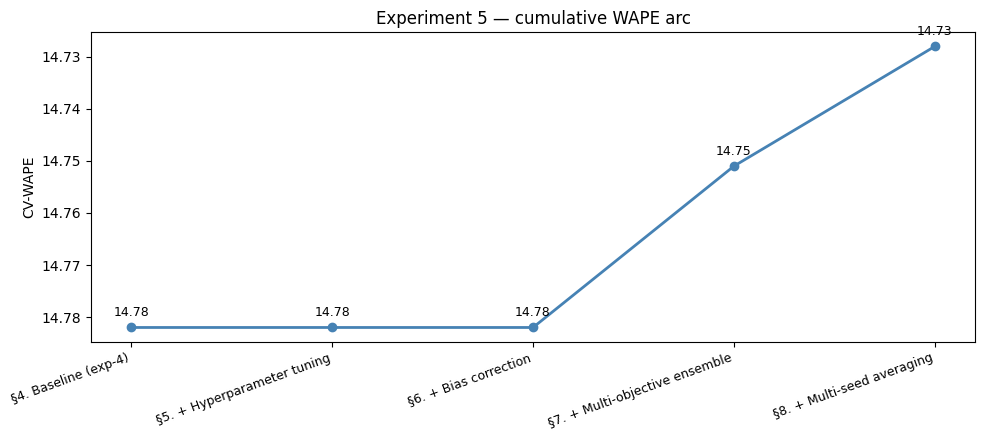

In [13]:
summary = pd.DataFrame([
    {"step": "§4. Baseline (exp-4)",              "CV-WAPE": BASELINE_WAPE, "std": BASELINE_STD},
    {"step": "§5. + Hyperparameter tuning",       "CV-WAPE": STEP1_WAPE,    "std": float(arr_step1.std())},
    {"step": "§6. + Bias correction",              "CV-WAPE": STEP2_WAPE,    "std": np.nan},
    {"step": "§7. + Multi-objective ensemble",     "CV-WAPE": STEP3_WAPE,    "std": STEP3_PER_FOLD.std()},
    {"step": "§8. + Multi-seed averaging",         "CV-WAPE": STEP4_WAPE,    "std": STEP4_PER_FOLD.std()},
]).round(3)

summary["Δ vs baseline"] = (BASELINE_WAPE - summary["CV-WAPE"]).round(3)
display(summary)

print()
print("Decisions applied to the final submission:")
print(f"  Hyperparameter tuning  : ✅ (always applied — STEP1_PARAMS)")
print(f"  Bias correction        : {'✅' if APPLY_BIAS else '❌'}")
print(f"  Multi-objective blend  : {'✅' if APPLY_ENSEMBLE else '❌'}")
print(f"  Multi-seed averaging   : {'✅' if APPLY_MULTISEED else '❌'}")

# Plot the WAPE arc
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(range(len(summary)), summary["CV-WAPE"], marker="o", color="steelblue", linewidth=2)
for i, (step, w) in enumerate(zip(summary["step"], summary["CV-WAPE"])):
    ax.annotate(f"{w:.2f}", (i, w), textcoords="offset points", xytext=(0, 8),
                ha="center", fontsize=9)
ax.set_xticks(range(len(summary)))
ax.set_xticklabels(summary["step"], rotation=20, ha="right", fontsize=9)
ax.set_ylabel("CV-WAPE")
ax.set_title("Experiment 5 — cumulative WAPE arc")
ax.invert_yaxis()
plt.tight_layout(); plt.show()